## ARIMA Forecasting and Evaluation

### Learning Goals
* Understand the components of an ARIMA$(p, d, q)$ model (autoregressive order, differencing, moving average).
* Implement chronological train-test splits for time-series forecasting to prevent data leakage.
* Evaluate forecast performance using Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE) against baselines.

---

### 1. ARIMA Models and Chronological Splits

An ARIMA model combines autoregressive terms ($p$), differencing to achieve stationarity ($d$), and moving-average error terms ($q$). 

> **Crucial Rule:** Time-series forecasting **must** respect chronology. A random train/test split leaks future information into the training set, resulting in overly optimistic and invalid evaluation metrics.

/home/prashant/Projects/mathematics-fundamentals/.venv/lib/python3.14/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


Out-of-Sample MAE:  0.0163
Out-of-Sample RMSE: 0.0188


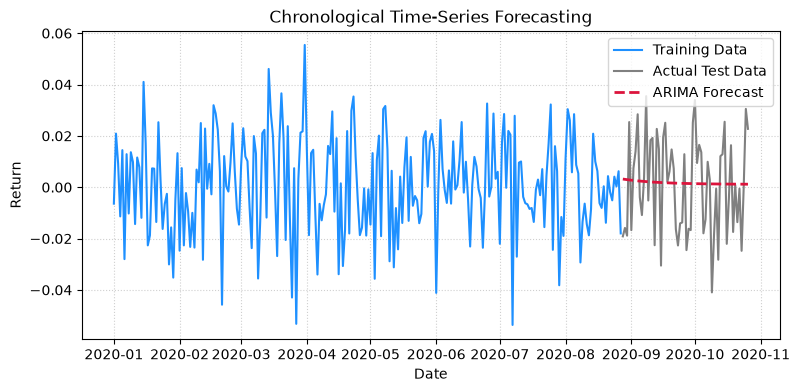

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error

rng = np.random.default_rng(19)
n = 300
dates = pd.date_range("2020-01-01", periods=n, freq="D")
returns = rng.normal(0.001, 0.02, n)
series = pd.Series(returns, index=dates)

# Strict chronological split (80% train, 20% test)
split = int(n * 0.8)
train = series.iloc[:split]
test = series.iloc[split:]

# Fit ARIMA(1, 0, 1) model
model = ARIMA(train, order=(1, 0, 1)).fit()
forecast = model.forecast(steps=len(test))
forecast.index = test.index

mae = mean_absolute_error(test, forecast)
rmse = np.sqrt(mean_squared_error(test, forecast))

print(f"Out-of-Sample MAE:  {mae:.4f}")
print(f"Out-of-Sample RMSE: {rmse:.4f}")

plt.figure(figsize=(9, 4))
plt.plot(train.index, train, color='dodgerblue', label="Training Data")
plt.plot(test.index, test, color='gray', label="Actual Test Data")
plt.plot(forecast.index, forecast, color='crimson', linestyle="--", linewidth=2, label="ARIMA Forecast")
plt.xlabel("Date")
plt.ylabel("Return")
plt.title("Chronological Time-Series Forecasting")
plt.legend()
plt.grid(linestyle=':', alpha=0.6)
plt.show()

### 2. Forecast Evaluation

Always compare sophisticated models against simple naive baselines (e.g., predicting zero return or the historical mean). A complex model is only valuable if it outperforms these baselines on unseen future test data.

---

### Exercises

Try each problem before running the verification code below:

1. Change the ARIMA order (e.g., try a pure random walk model ARIMA$(0, 1, 0)$) and compare error metrics.
2. Calculate the zero-return baseline RMSE for the test set.
3. Explain why model selection and hyperparameter tuning must be performed strictly without looking at the final test period.

In [2]:
# --- Exercise Verification & Explanations ---
print("=== Exercise Solutions & Checks ===")

# Exercise 2: Zero-return baseline RMSE
zero_forecast = pd.Series(0.0, index=test.index)
baseline_rmse = np.sqrt(mean_squared_error(test, zero_forecast))

print(f"\n2. Zero-Return Baseline RMSE: {baseline_rmse:.4f}")
print(f"   - ARIMA Model RMSE:           {rmse:.4f}")

print("\n3. Avoiding Data Leakage in Test Periods:")
print("   - Looking at the test period during model tuning leads to overfitting and selection bias,")
print("     producing overly optimistic out-of-sample error estimates that fail in production.")

=== Exercise Solutions & Checks ===

2. Zero-Return Baseline RMSE: 0.0187
   - ARIMA Model RMSE:           0.0188

3. Avoiding Data Leakage in Test Periods:
   - Looking at the test period during model tuning leads to overfitting and selection bias,
     producing overly optimistic out-of-sample error estimates that fail in production.
